# EDA — Malla Vial Integral de Bogotá D.C. y Puentes

Este cuaderno realiza el **Análisis Exploratorio de Datos (EDA)** de las dos capas geoespaciales base del proyecto:

1. **Malla Vial Integral de Bogotá D.C.** (`Malla_Vial_Integral_Bogota_D_C (3).geojson`) — red vial (líneas), unidad espacial base del proyecto.
2. **Puentes** (`Puente.gpkg`) — infraestructura de puentes peatonales/vehiculares (polígonos).

El cuaderno está organizado así:

1. Diccionario de variables (Malla Vial y Puentes)
2. Carga de datos
3. EDA — Malla Vial Integral
4. EDA — Puentes
5. Resumen y hallazgos clave


## 1. Diccionario de variables

> Los nombres de columnas provienen directamente de los metadatos oficiales del IDECA / Catastro Bogotá. Cuando el significado exacto de un código no está documentado en la fuente, se indica como *"código interno / sin documentación oficial"* y se infiere su naturaleza a partir de los valores observados en los datos.

### 1.1 Malla Vial Integral de Bogotá D.C. (`malla`)

43 columnas, 136.957 registros (segmentos viales).

| Variable | Tipo | Descripción |
|---|---|---|
| `OBJECTID` | int | Identificador único interno del registro (ArcGIS). |
| `MVICCALZAD` | float | Código de la calzada asociada al segmento vial. |
| `MVICCAT` | str/object | Código catastral (CHIP/manzana) de referencia del segmento. |
| `MVITIPO` | str | Tipo de vía según nomenclatura oficial de Bogotá: `CL` (Calle), `KR` (Carrera), `AC` (Avenida Calle), `AK` (Avenida Carrera), `DG` (Diagonal), `TV` (Transversal). |
| `MVINOMBRE` | str | Nombre/nomenclatura del segmento vial (ej. `8A -57`). |
| `MVINALTERN` | str | Nombre alterno o coloquial de la vía (ej. `AUTOPISTA NORTE`, `AVENIDA EL DORADO`). |
| `MVINPRINCI` | str | Código de la vía principal a la que pertenece el segmento. |
| `MVINGENERA` | str | Código de la vía generadora (vía de referencia para la nomenclatura). |
| `MVINANTIGU` | str | Nomenclatura vial antigua/histórica del segmento. |
| `MVIETIQUET` | str | Etiqueta de nomenclatura vial completa. |
| `MVISVIA` | str | Estado de la vía: `B` (Bueno), `SD` (Sin Dato), `FT` (Fuera de Trazado?), `TF`, `N` (No existe/proyectada). |
| `MVICIV` | float | Código de la Cartografía / Identificador Vial (CIV) del segmento. |
| `MVINVIA` | int | Número de vía (correlativo). |
| `MVIEVIA` | str | Estado de ejecución de la vía: `M` (Malla vial existente), `B`, `R`, `SD` (sin dato). |
| `MVIFRIGHT` | float | Código del segmento adyacente en el costado derecho (from). |
| `MVITRIGHT` | float | Código del segmento adyacente en el costado derecho (to). |
| `MVIFLEFT` | float | Código del segmento adyacente en el costado izquierdo (from). |
| `MVITLEFT` | float | Código del segmento adyacente en el costado izquierdo (to). |
| `MVITM` | int | Indicador/código de Transmilenio asociado al segmento. |
| `MVICM` | int | Indicador/código de ciclorruta asociado al segmento. |
| `MVINUMC` | float | Número de calzadas del segmento vial. |
| `MVIACAL` | float | Ancho de calzada (m aprox.). |
| `MVIEFUN` | str | Estado funcional de la vía (`SD` = Sin Dato en la práctica totalidad de registros). |
| `MVITCONE` | str/int | Tipo de conexión del segmento en la topología de red (1 a 5; `5` = mayoría, tramo estándar). |
| `NAME` | str | Nombre general asociado al segmento (frecuentemente `BOGOTA`). |
| `MUNICIPIO` | str | Municipio (prácticamente 100% `BOGOTA`). |
| `PREFIJO` | str | Prefijo de orientación/zona de la nomenclatura vial (`S` = Sur, `E` = Este, `SE` = Sur-Este, vacío = sin prefijo/Norte-Centro). |
| `MVIVEL` | object | Columna sin datos (100% nulos/None) — reservada para velocidad, no poblada en esta fuente. |
| `MVIBICI` | object | Columna sin datos (100% nulos/None) — reservada para infraestructura ciclística, no poblada en esta fuente. |
| `MVIRCAR` | object | Columna sin datos (100% nulos/None) — reservada, no poblada en esta fuente. |
| `MVIESTV` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVITC` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVIRAPS` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVITSUP` | int | Tipo de superficie del pavimento (código 0–12; ver value_counts en el EDA). |
| `MVIMONIT` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVICODIGO` | int | Código único oficial del segmento vial (identificador de malla vial IDECA). |
| `CREADOR` | str | Usuario que creó el registro en el sistema (mayoritariamente nulo). |
| `CREADOR_DATE` | datetime | Fecha de creación del registro. |
| `EDITOR` | str | Usuario que editó por última vez el registro (`SIGADMIN` en casi todos los casos). |
| `EDITOR_DATE` | datetime | Fecha de la última edición del registro. |
| `MVI_VELREG` | float | Velocidad reglamentaria de la vía (km/h). |
| `Shape__Length` | float | Longitud de la geometría calculada por el sistema de origen. Se conserva tal cual venía en el archivo fuente (grados decimales, CRS original `EPSG:4326`); no se recalcula tras la reproyección. |
| `geometry` | geometry | Geometría del segmento vial: `LineString` o `MultiLineString`. Fuente original en `EPSG:4326` (WGS84); **estandarizada en este cuaderno a `EPSG:3116`** (MAGNA-SIRGAS / Bogotá, proyectado, unidades en metros). |

### 1.2 Puentes (`puentes`)

6 columnas, 1.212 registros.

| Variable | Tipo | Descripción |
|---|---|---|
| `PueCodigo` | int | Identificador único oficial del puente. |
| `PueTipo` | int | Tipo de puente (código): `1` = Puente vehicular, `2` = Puente peatonal (clasificación inferida a partir de la frecuencia y el contexto vial; ver EDA). |
| `PueUbicaci` | str | Descripción textual de la ubicación del puente (ej. intersección de vías o accidente geográfico que cruza). |
| `SHAPE_Length` | float | Perímetro de la geometría calculado por el sistema de origen. Se conserva tal cual venía en el archivo fuente (grados decimales, CRS original `EPSG:4686`); no se recalcula tras la reproyección. |
| `SHAPE_Area` | float | Área de la geometría calculada por el sistema de origen (grados decimales al cuadrado, CRS original `EPSG:4686`). |
| `geometry` | geometry | Geometría del puente: `MultiPolygon`. Fuente original en `EPSG:4686` (MAGNA-SIRGAS / Bogotá geográfico); **estandarizada en este cuaderno a `EPSG:3116`** (MAGNA-SIRGAS / Bogotá, proyectado, unidades en metros). |

### 1.3 Estandarización de CRS

Ambas capas llegan en sistemas de referencia distintos y no proyectados (`EPSG:4326` y `EPSG:4686`), lo cual impide calcular longitudes/áreas reales en metros y complica cualquier análisis espacial conjunto (uniones, distancias, buffers). Por eso, **al inicio de este cuaderno ambas capas se reproyectan a `EPSG:3116`** (MAGNA-SIRGAS / Colombia Bogotá zone), el sistema de referencia proyectado oficial recomendado para trabajo cartográfico de precisión en Bogotá D.C., con unidades en metros.


## 2. Carga de librerías y datos

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)


In [2]:
# Carga de las dos capas base
malla = gpd.read_file("./Malla_Vial_Integral_Bogota_D_C (3).geojson")
puentes = gpd.read_file("./Puente.gpkg")

print("Malla vial:", malla.shape, "| CRS original:", malla.crs)
print("Puentes   :", puentes.shape, "| CRS original:", puentes.crs)


Malla vial: (136957, 43) | CRS original: EPSG:4326
Puentes   : (1212, 6) | CRS original: EPSG:4686


### 2.1 Estandarización de CRS a EPSG:3116

Se reproyectan ambas capas a `EPSG:3116` (MAGNA-SIRGAS / Colombia Bogotá zone, proyectado, unidades en metros). A partir de aquí, **todo el EDA y todos los mapas usan esta capa ya estandarizada.**

In [3]:
malla = malla.to_crs(3116)
puentes = puentes.to_crs(3116)

print("Malla vial   -> CRS:", malla.crs)
print("Puentes      -> CRS:", puentes.crs)

Malla vial   -> CRS: EPSG:3116
Puentes      -> CRS: EPSG:3116


## 3. EDA — Malla Vial Integral

### 3.1 Estructura general

In [4]:
print("Tipo de geometría:", malla.geom_type.unique())
print("CRS:", malla.crs)
malla.info()

Tipo de geometría: ['LineString' 'MultiLineString' None]
CRS: EPSG:3116
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 136957 entries, 0 to 136956
Data columns (total 43 columns):
 #   Column         Non-Null Count   Dtype              
---  ------         --------------   -----              
 0   OBJECTID       136957 non-null  int32              
 1   MVICCALZAD     126610 non-null  float64            
 2   MVICCAT        136922 non-null  object             
 3   MVITIPO        136922 non-null  object             
 4   MVINOMBRE      136924 non-null  object             
 5   MVINALTERN     136922 non-null  object             
 6   MVINPRINCI     136922 non-null  object             
 7   MVINGENERA     136922 non-null  object             
 8   MVINANTIGU     136922 non-null  object             
 9   MVIETIQUET     136922 non-null  object             
 10  MVISVIA        136957 non-null  object             
 11  MVICIV         136922 non-null  float64            
 12  MVINVI

### 3.2 Vista previa de los datos

In [5]:
malla.head()

,OBJECTID,MVICCALZAD,MVICCAT,MVITIPO,MVINOMBRE,MVINALTERN,MVINPRINCI,MVINGENERA,MVINANTIGU,MVIETIQUET,MVISVIA,MVICIV,MVINVIA,MVIEVIA,MVIFRIGHT,MVITRIGHT,MVIFLEFT,MVITLEFT,MVITM,MVICM,MVINUMC,MVIACAL,MVIEFUN,MVITCONE,NAME,MUNICIPIO,PREFIJO,MVIVEL,MVIBICI,MVIRCAR,MVIESTV,MVITC,MVIRAPS,MVITSUP,MVIMONIT,MVICODIGO,CREADOR,CREADOR_DATE,EDITOR,EDITOR_DATE,MVI_VELREG,Shape__Length,geometry
0,1,168175.0,18005353,KR,,,008A0000E0,05700000S0,KR 14A E,KR 8A E,SD,18006831.0,0,M,2.0,98.0,99.0,97.0,0,0,1.0,3.5,SD,5,8A -57,BOGOTA,SE,None,None,None,0,0,0,2,0,96282,None,NaT,SIGADMIN,2014-01-22 19:06:43+00:00,30.0,0.000320,"LINESTRING (997702.139 993255.081, 997674.788 ..."
1,2,34104.0,8001090,CL,,,04200000S0,0980000000,CL 42 S,CL 42 S,B,8000857.0,0,M,2.0,98.0,99.0,97.0,0,0,1.0,4.0,SD,5,42 -98,BOGOTA,S,None,None,None,0,0,0,6,0,62558,None,NaT,SIGADMIN,2014-01-22 17:48:21+00:00,30.0,0.000233,"LINESTRING (989012.577 1005585.74, 988998.75 1..."
2,3,34338.0,2000900,TV,,,00600000E0,0970000000,TV 6 E,TV 6 E,B,1005995.0,0,M,2.0,98.0,99.0,97.0,0,0,2.0,5.2,SD,5,6 E-97,BOGOTA,,None,None,None,0,0,0,1,0,33964,None,NaT,SIGADMIN,2014-01-22 18:52:11+00:00,NaN,0.000862,"LINESTRING (1006180.996 1007998.51, 1006201.46..."
3,4,3192.0,1000290,CL,,,183B000000,0080000000,CL 183B,CL 183B,B,1000874.0,0,R,2.0,98.0,99.0,97.0,0,0,2.0,6.5,SD,5,183B-8,BOGOTA,,None,None,None,0,0,0,6,0,29147,None,NaT,SIGADMIN,2014-01-22 19:20:55+00:00,30.0,0.001055,"LINESTRING (1005380.357 1018221.924, 1005369.9..."
4,5,33331.0,8001681,KR,,,0810000000,008A000000,KR 84D,KR 81,B,8001417.0,0,M,2.0,98.0,99.0,97.0,0,0,NaN,0.0,SD,5,81-8A,BOGOTA,,None,None,None,0,0,0,12,0,133742,None,NaT,SIGADMIN,2014-01-22 18:26:11+00:00,30.0,0.000533,"LINESTRING (992300.356 1005275.881, 992343.913..."


### 3.3 Valores nulos

Se calcula el porcentaje de valores faltantes por columna para identificar qué variables requieren limpieza o no aportan información (columnas constantes o 100% vacías).

In [6]:
nulos = malla.isna().sum().sort_values(ascending=False)
pct_nulos = (nulos / len(malla) * 100).round(2)
resumen_nulos = pd.DataFrame({'n_nulos': nulos, 'pct_nulos': pct_nulos})
resumen_nulos[resumen_nulos['n_nulos'] > 0]

,n_nulos,pct_nulos
MVIRCAR,136957,100.00
MVIBICI,136957,100.00
MVIVEL,136957,100.00
CREADOR_DATE,136892,99.95
CREADOR,136892,99.95
MVI_VELREG,26679,19.48
MVINUMC,24670,18.01
MVICCALZAD,10347,7.55
MVIACAL,213,0.16
MVIETIQUET,35,0.03


In [7]:
# Columnas completamente vacías o constantes (no aportan información al análisis)
constantes = [c for c in malla.columns if malla[c].nunique(dropna=False) <= 1]
print("Columnas sin variabilidad (constantes o 100% nulas):")
print(constantes)

Columnas sin variabilidad (constantes o 100% nulas):
['MVIVEL', 'MVIBICI', 'MVIRCAR', 'MVIESTV', 'MVITC', 'MVIRAPS', 'MVIMONIT']


### 3.4 Estadística descriptiva — variables numéricas

In [8]:
malla.describe().T

,count,mean,std,min,25%,50%,75%,max
OBJECTID,136957.0,6.847900e+04,3.953622e+04,1.000000e+00,3.424000e+04,6.847900e+04,1.027180e+05,1.369570e+05
MVICCALZAD,126610.0,2.673193e+06,1.094874e+07,0.000000e+00,5.768425e+04,1.597475e+05,2.264758e+05,5.001753e+07
MVICIV,136922.0,9.016357e+09,2.784308e+11,0.000000e+00,6.001822e+06,1.000724e+07,1.800064e+07,8.620090e+12
MVINVIA,136957.0,3.000942e-03,6.016558e-02,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00
MVIFRIGHT,136922.0,2.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
MVITRIGHT,136922.0,9.800000e+01,0.000000e+00,9.800000e+01,9.800000e+01,9.800000e+01,9.800000e+01,9.800000e+01
MVIFLEFT,136922.0,9.900000e+01,0.000000e+00,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01
MVITLEFT,136929.0,9.700000e+01,0.000000e+00,9.700000e+01,9.700000e+01,9.700000e+01,9.700000e+01,9.700000e+01
MVITM,136957.0,2.131326e-02,1.444270e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
MVICM,136957.0,1.826924e-01,3.864155e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


### 3.5 Distribución de variables categóricas clave

`MVITIPO` (tipo de vía), `MVISVIA` (estado), `MVIEVIA` (estado de ejecución) y `PREFIJO` (orientación).

In [9]:
cat_cols = ['MVITIPO', 'MVISVIA', 'MVIEVIA', 'PREFIJO', 'MVITSUP']
for c in cat_cols:
    print(f"--- {c} ---")
    print(malla[c].value_counts(dropna=False))
    print()


--- MVITIPO ---
MVITIPO
CL      51666
KR      51145
AK       7744
         7513
AC       6849
TV       6214
DG       5791
None       35
Name: count, dtype: int64

--- MVISVIA ---
MVISVIA
B     78127
SD    29489
FT    13377
TF    12610
N      3354
Name: count, dtype: int64

--- MVIEVIA ---
MVIEVIA
M     55259
B     33901
R     29583
SD    18214
Name: count, dtype: int64

--- PREFIJO ---
PREFIJO
        69164
S       56836
SE       9762
E        1159
None       35
O           1
Name: count, dtype: int64

--- MVITSUP ---
MVITSUP
2     49959
12    38861
1     23693
6     21310
8      1390
4       819
5       728
3       194
0         3
Name: count, dtype: int64



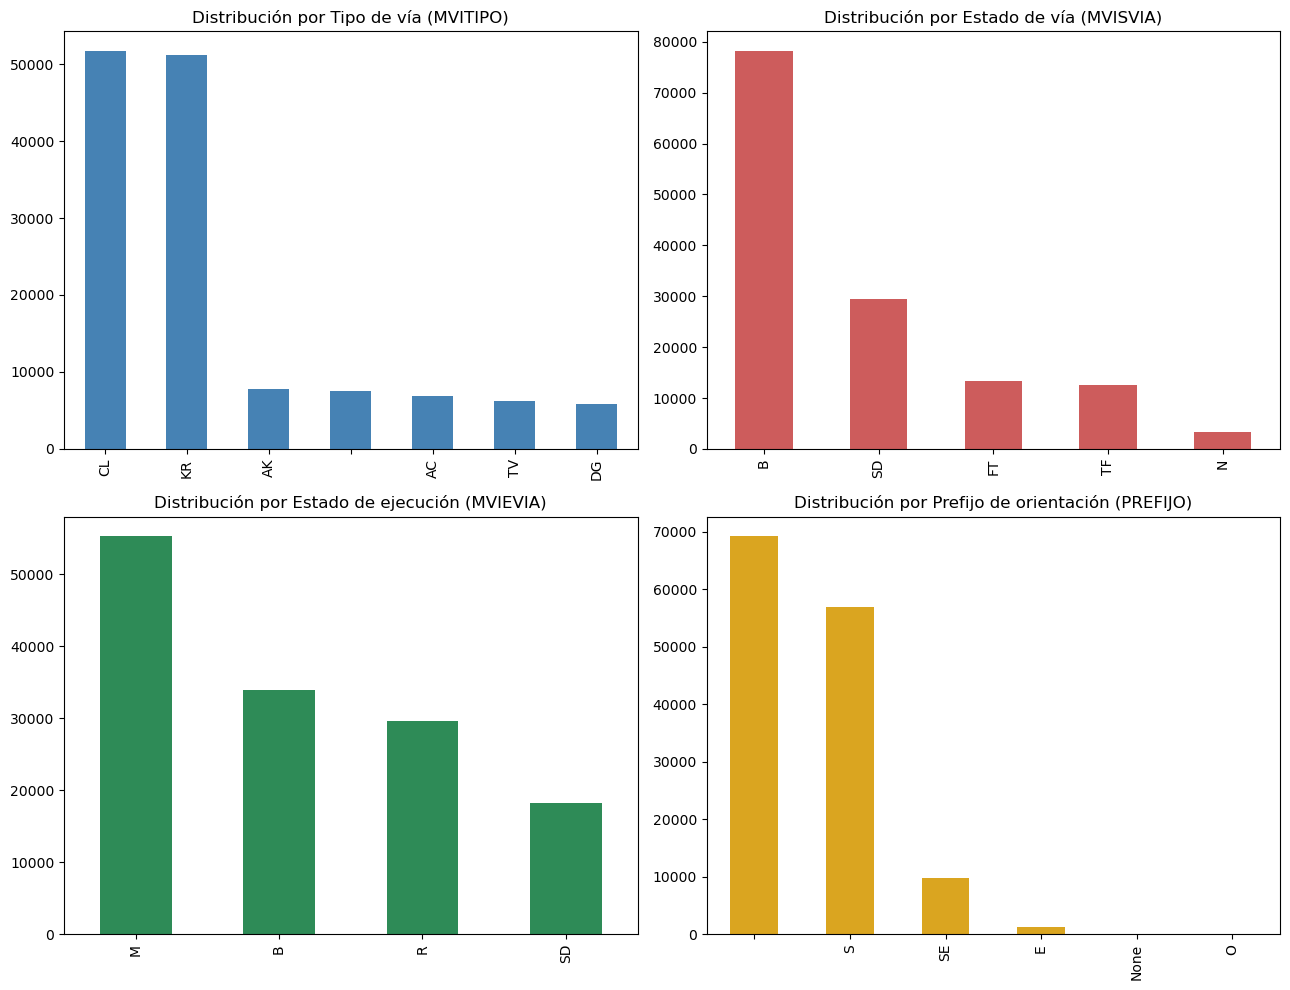

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

malla['MVITIPO'].value_counts().plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribución por Tipo de vía (MVITIPO)')
axes[0,0].set_xlabel('')

malla['MVISVIA'].value_counts().plot(kind='bar', ax=axes[0,1], color='indianred')
axes[0,1].set_title('Distribución por Estado de vía (MVISVIA)')
axes[0,1].set_xlabel('')

malla['MVIEVIA'].value_counts().plot(kind='bar', ax=axes[1,0], color='seagreen')
axes[1,0].set_title('Distribución por Estado de ejecución (MVIEVIA)')
axes[1,0].set_xlabel('')

malla['PREFIJO'].value_counts(dropna=False).plot(kind='bar', ax=axes[1,1], color='goldenrod')
axes[1,1].set_title('Distribución por Prefijo de orientación (PREFIJO)')
axes[1,1].set_xlabel('')

plt.tight_layout()
plt.show()

### 3.6 Longitud de los segmentos viales

El campo original `Shape__Length` viene en grados decimales (CRS fuente `EPSG:4326`) y no es directamente interpretable como distancia. Como la capa ya está estandarizada a `EPSG:3116` (metros), se calcula una longitud real en metros a partir de la geometría reproyectada.

count    136956.000000
mean         68.484676
std          91.849683
min           0.034799
25%          31.293946
50%          50.186202
75%          83.325049
max        5035.716928
Name: longitud_m, dtype: float64


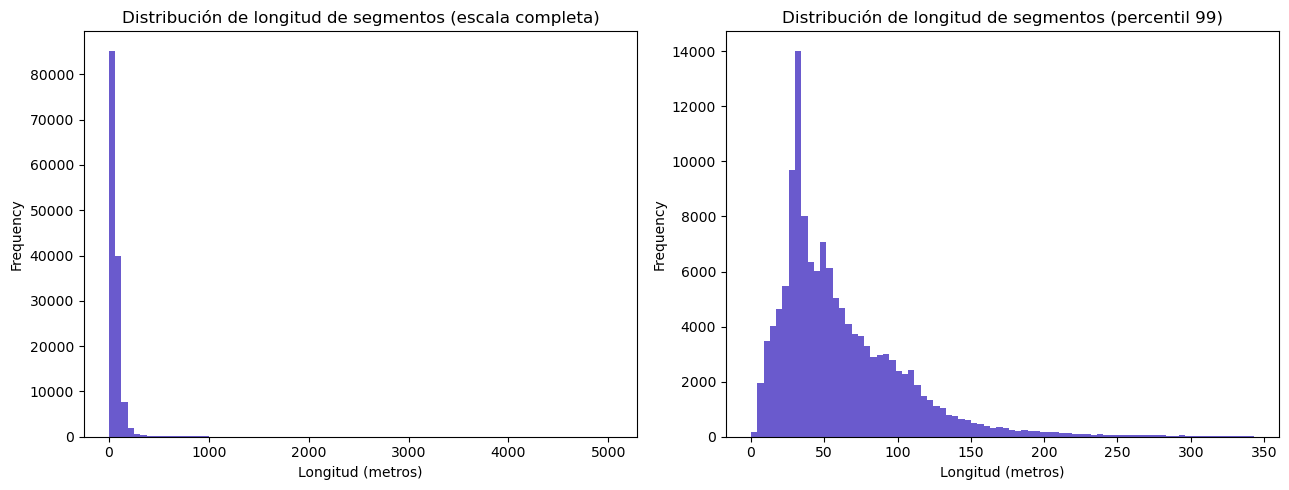

In [11]:
malla['longitud_m'] = malla.geometry.length

print(malla['longitud_m'].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
malla['longitud_m'].plot(kind='hist', bins=80, ax=ax[0], color='slateblue')
ax[0].set_title('Distribución de longitud de segmentos (escala completa)')
ax[0].set_xlabel('Longitud (metros)')

malla[malla['longitud_m'] < malla['longitud_m'].quantile(0.99)]['longitud_m'].plot(
    kind='hist', bins=80, ax=ax[1], color='slateblue')
ax[1].set_title('Distribución de longitud de segmentos (percentil 99)')
ax[1].set_xlabel('Longitud (metros)')

plt.tight_layout()
plt.show()

### 3.7 Geometrías nulas o inválidas

La malla vial reporta 1 registro sin geometría (`geometry: 136956 non-null` sobre 136957 filas). Se identifica explícitamente.

In [12]:
geom_nula = malla[malla.geometry.isna()]
print(f"Registros con geometría nula: {len(geom_nula)}")

geom_invalida = malla[~malla.geometry.isna() & ~malla.geometry.is_valid]
print(f"Registros con geometría inválida: {len(geom_invalida)}")

Registros con geometría nula: 1
Registros con geometría inválida: 0


### 3.8 Visualización espacial de la malla vial

La capa incluye zonas rurales muy extensas al sur (localidad de Sumapaz) que representan una fracción mínima de los segmentos (~0.3%) pero estiran la extensión del mapa y dificultan ver el detalle de la malla urbana. Se muestra primero la extensión completa y luego un recorte acotado a la zona urbana (límites en metros, `EPSG:3116`).

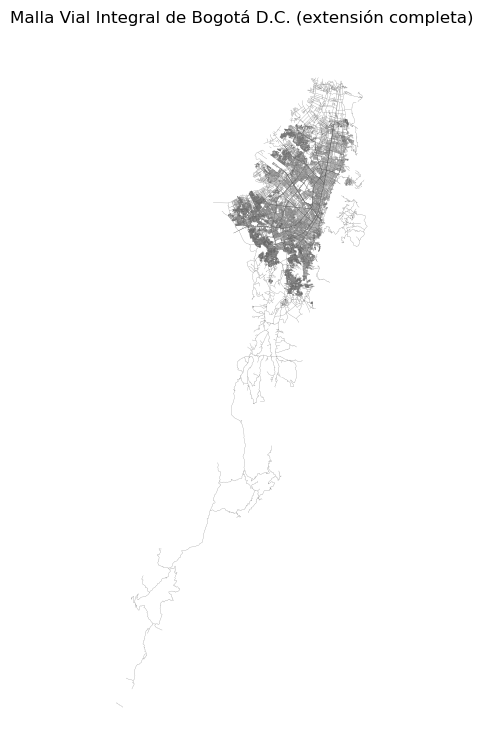

In [13]:
fig, ax = plt.subplots(figsize=(9, 9))
malla.plot(ax=ax, linewidth=0.15, color='dimgray')
ax.set_title('Malla Vial Integral de Bogotá D.C. (extensión completa)')
ax.set_axis_off()
plt.show()

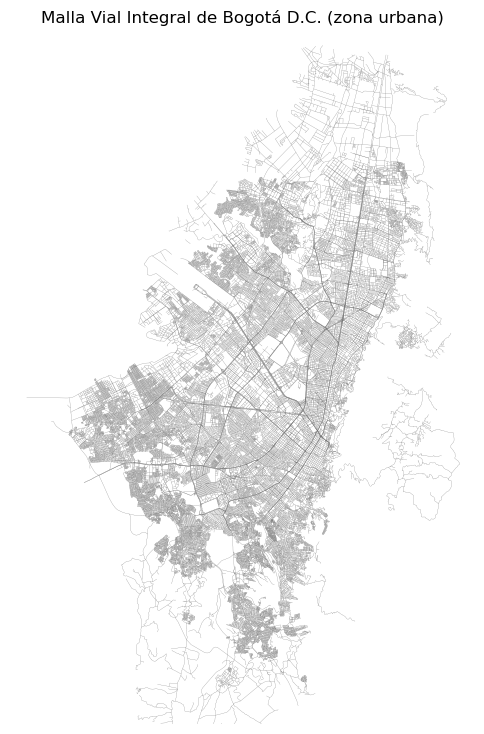

In [14]:
# Recorte visual a la zona urbana (excluye Sumapaz y bordes rurales), en metros EPSG:3116
fig, ax = plt.subplots(figsize=(9, 9))
malla.plot(ax=ax, linewidth=0.15, color='dimgray')
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial Integral de Bogotá D.C. (zona urbana)')
ax.set_axis_off()
plt.show()

### 3.9 Duplicados

In [15]:
print("Registros duplicados (todas las columnas):", malla.duplicated().sum())
print("OBJECTID duplicados:", malla['OBJECTID'].duplicated().sum())
print("MVICODIGO duplicados:", malla['MVICODIGO'].duplicated().sum())

Registros duplicados (todas las columnas): 0
OBJECTID duplicados: 0
MVICODIGO duplicados: 0


## 4. EDA — Puentes

### 4.1 Estructura general

In [16]:
print("Tipo de geometría:", puentes.geom_type.unique())
print("CRS:", puentes.crs)
puentes.info()

Tipo de geometría: ['MultiPolygon']
CRS: EPSG:3116
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   PueCodigo     1212 non-null   int32   
 1   PueTipo       1212 non-null   int32   
 2   PueUbicaci    1212 non-null   object  
 3   SHAPE_Length  1212 non-null   float64 
 4   SHAPE_Area    1212 non-null   float64 
 5   geometry      1212 non-null   geometry
dtypes: float64(2), geometry(1), int32(2), object(1)
memory usage: 47.5+ KB


### 4.2 Vista previa de los datos

In [17]:
puentes.head()

,PueCodigo,PueTipo,PueUbicaci,SHAPE_Length,SHAPE_Area,geometry
0,22156629,1,Avenida José Celestino Mutis por Avenida del C...,0.000971,4.708416e-08,"MULTIPOLYGON (((998280.597 1007762.268, 998280..."
1,24119247,1,Avenida José Celestino Mutis por Avenida del C...,0.000970,4.394591e-08,"MULTIPOLYGON (((998235.48 1007693.897, 998233...."
2,24119314,1,Avenida Jorge Uribe Botero por Avenida de los ...,0.001157,2.512141e-08,"MULTIPOLYGON (((1004041.067 1014743.721, 10040..."
3,22158560,1,Avenida Paseo Del Country por Avenida Carlos L...,0.000605,1.620756e-08,"MULTIPOLYGON (((1003223.483 1009834.876, 10032..."
4,22158594,1,Avenida Laureano Gómez por Avenida Carlos Ller...,0.000729,2.609475e-08,"MULTIPOLYGON (((1003191.943 1009797.853, 10032..."


### 4.3 Valores nulos

In [18]:
nulos_p = puentes.isna().sum()
print(nulos_p)
print("\nNo hay valores nulos en el dataset de Puentes." if nulos_p.sum() == 0 else "")

PueCodigo       0
PueTipo         0
PueUbicaci      0
SHAPE_Length    0
SHAPE_Area      0
geometry        0
dtype: int64

No hay valores nulos en el dataset de Puentes.


### 4.4 Estadística descriptiva — variables numéricas

In [19]:
puentes.describe().T

,count,mean,std,min,25%,50%,75%,max
PueCodigo,1212.0,2.342624e+07,9.572716e+05,2.214214e+07,2.216003e+07,2.411942e+07,2.412479e+07,2.419045e+07
PueTipo,1212.0,1.433993e+00,4.958286e-01,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
SHAPE_Length,1212.0,1.849275e-03,2.325624e-03,3.535513e-05,3.791207e-04,7.734528e-04,2.668110e-03,2.276622e-02
SHAPE_Area,1212.0,6.255618e-08,1.254423e-07,3.563281e-13,5.099153e-09,1.725575e-08,5.563386e-08,1.161435e-06


### 4.5 Distribución de `PueTipo`

`PueTipo` toma 2 valores (1 y 2). No hay diccionario de dominio adjunto al archivo, por lo que se reporta la distribución observada; se recomienda confirmar la codificación exacta con la entidad fuente (IDU/IDECA).

PueTipo
1    686
2    526
Name: count, dtype: int64


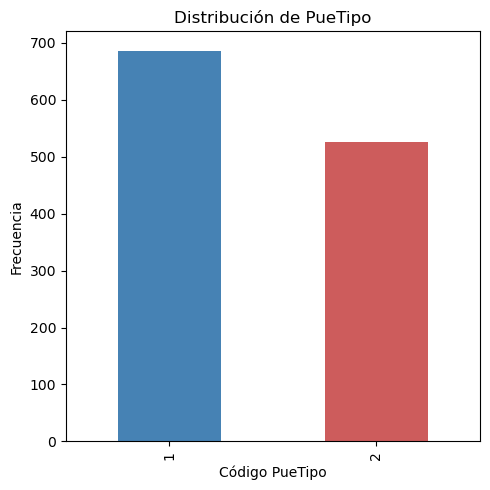

In [20]:
print(puentes['PueTipo'].value_counts())

fig, ax = plt.subplots(figsize=(5,5))
puentes['PueTipo'].value_counts().plot(kind='bar', color=['steelblue','indianred'], ax=ax)
ax.set_title('Distribución de PueTipo')
ax.set_xlabel('Código PueTipo')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### 4.6 Ubicaciones más frecuentes (`PueUbicaci`)

In [21]:
print("Valores únicos en PueUbicaci:", puentes['PueUbicaci'].nunique())
puentes['PueUbicaci'].value_counts().head(15)

Valores únicos en PueUbicaci: 1124


PueUbicaci
Av. Boyacá con Calle 181 (costado oriental)                 4
Vereda San Antonio                                          4
Río Teusaca                                                 3
Avenida Jose Celestino Mutis                                3
Avenida Ciudad de Quito por Avenida Jorge Eliecer Gaitan    3
Avenida Centenario por Avenida Boyacá                       3
Diagonal 7ABISC (costado occidental) por Transversal 73B    3
Avenida Centenario (Calle 17)  Con el Rio Bogotá            3
AvJorge Eliecer(AC26) por Av C de Cali(AK86)                3
AV. CARRERA 15 - AV. CALLE 170                              2
Avenida La Sirena por KR 54                                 2
Avenida del Sur por CL 57D S                                2
Avenida del Sur por TV 73I Costado Occidental               2
Via Vereda San Jose - Drenaje R. Sumapaz                    2
Avenida Callejas por Carrera 11                             2
Name: count, dtype: int64

### 4.7 Longitud y área de los puentes

Los campos originales `SHAPE_Length` y `SHAPE_Area` vienen en grados decimales (CRS fuente `EPSG:4686`). Con la capa ya estandarizada a `EPSG:3116` se calculan el perímetro y el área reales en metros.

       perimetro_m       area_m2
count  1212.000000   1212.000000
mean    204.859607    767.867034
std     257.636884   1539.046243
min       3.914938      0.004372
25%      41.993129     62.579315
50%      85.655996    211.719576
75%     295.340470    682.641250
max    2521.387858  14249.445753


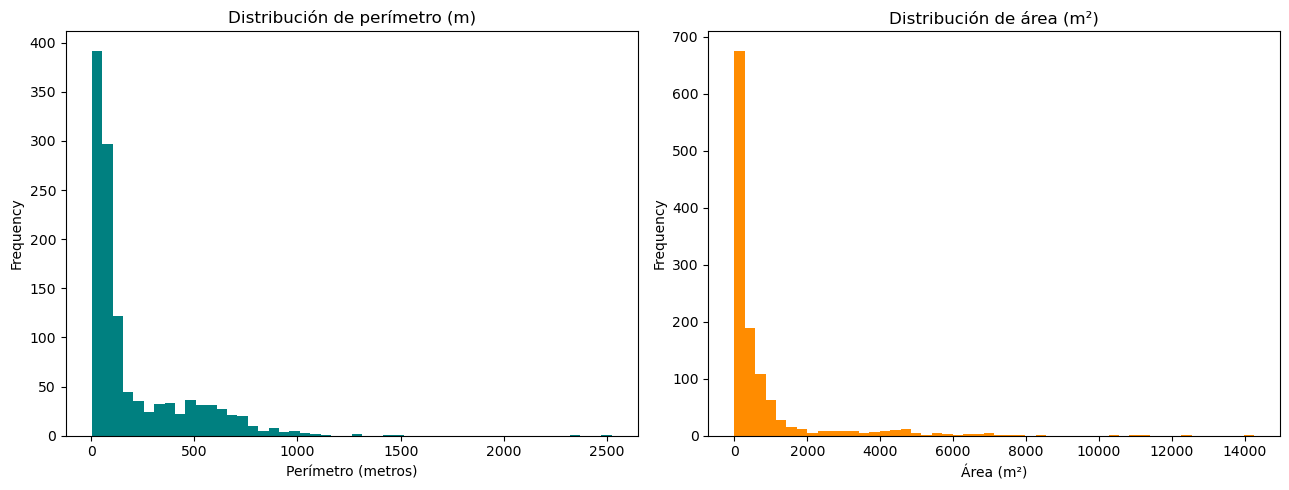

In [22]:
puentes['perimetro_m'] = puentes.geometry.length
puentes['area_m2'] = puentes.geometry.area

print(puentes[['perimetro_m', 'area_m2']].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
puentes['perimetro_m'].plot(kind='hist', bins=50, ax=ax[0], color='teal')
ax[0].set_title('Distribución de perímetro (m)')
ax[0].set_xlabel('Perímetro (metros)')

puentes['area_m2'].plot(kind='hist', bins=50, ax=ax[1], color='darkorange')
ax[1].set_title('Distribución de área (m²)')
ax[1].set_xlabel('Área (m²)')

plt.tight_layout()
plt.show()

### 4.8 Duplicados

In [23]:
print("Registros duplicados (todas las columnas):", puentes.duplicated().sum())
print("PueCodigo duplicados:", puentes['PueCodigo'].duplicated().sum())

Registros duplicados (todas las columnas): 0
PueCodigo duplicados: 0


### 4.9 Visualización espacial de los puentes

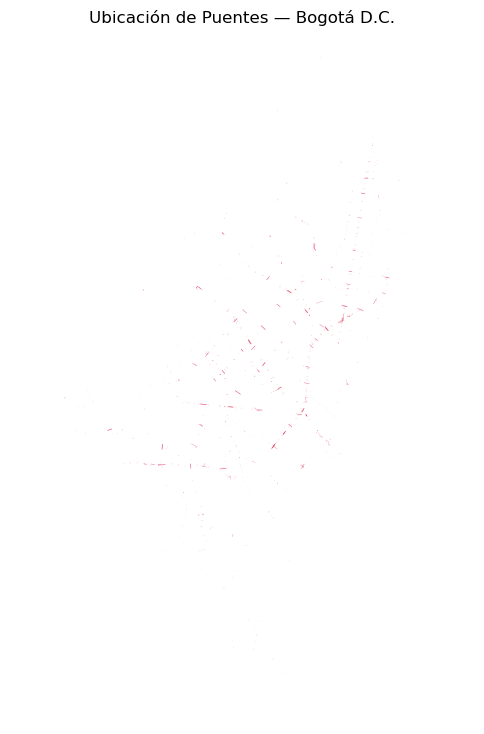

In [26]:
fig, ax = plt.subplots(figsize=(9, 9))
puentes.plot(ax=ax, color='crimson', markersize=1)
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Ubicación de Puentes — Bogotá D.C.')
ax.set_axis_off()
plt.show()

### 4.10 Contexto conjunto: Malla vial + Puentes

Como ambas capas ya están estandarizadas al mismo CRS (`EPSG:3116`), se pueden visualizar y cruzar directamente sin necesidad de reproyección adicional. Se muestra el mapa conjunto acotado a la zona urbana.

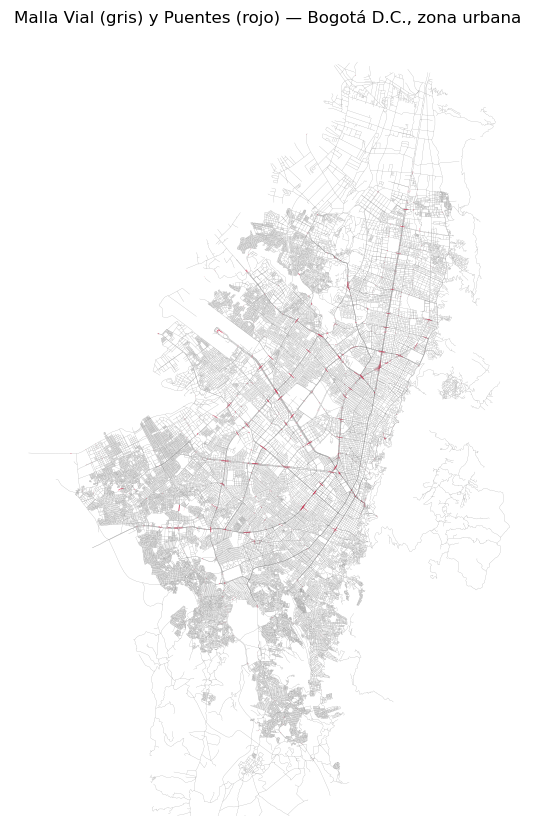

In [28]:
fig, ax = plt.subplots(figsize=(10, 10))
puentes.plot(ax=ax, color='crimson', markersize=3, zorder=2)
malla.plot(ax=ax, linewidth=0.12, color='gray', zorder=1)

ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial (gris) y Puentes (rojo) — Bogotá D.C., zona urbana')
ax.set_axis_off()
plt.show()

## 5. Resumen y hallazgos clave

**Estandarización de CRS**
- Ambas capas se reproyectaron a `EPSG:3116` (MAGNA-SIRGAS / Bogotá, proyectado, metros) desde sus CRS originales (`EPSG:4326` la malla vial, `EPSG:4686` los puentes). Esto permite calcular longitudes/áreas reales en metros y habilita cruces espaciales directos entre ambas capas.

**Malla Vial Integral (136.957 segmentos)**
- Geometría `LineString`/`MultiLineString`; 1 registro sin geometría. CRS estandarizado a `EPSG:3116`.
- Columnas `MVIVEL`, `MVIBICI`, `MVIRCAR` están 100% vacías y `MVIESTV`, `MVITC`, `MVIRAPS`, `MVIMONIT` son constantes en 0 — no aportan información y son candidatas a eliminarse en la fase de estandarización.
- `MVITIPO` muestra predominio de `CL` (Calle, 51.666) y `KR` (Carrera, 51.145), seguidas de `AK`, `AC`, `TV`, `DG`; 7.513 registros sin tipo asignado.
- `MVIEFUN` está informado como `SD` (Sin Dato) en prácticamente el 100% de los registros — variable no utilizable.
- Existen columnas con nulos moderados (`MVICCALZAD`, `MVINUMC`, `MVI_VELREG`, `CREADOR`) que deben tratarse antes de análisis de red.

**Puentes (1.212 registros)**
- Geometría `MultiPolygon`. CRS estandarizado a `EPSG:3116`.
- Sin valores nulos en ninguna columna.
- `PueTipo` tiene 2 categorías (686 vs. 526 registros); se recomienda confirmar su significado exacto con la fuente oficial.
- `PueUbicaci` es texto libre con alta cardinalidad (mayoría de valores únicos), útil como referencia pero no como variable categórica directa.
- Sin registros duplicados por `PueCodigo`.

**Próximos pasos sugeridos para la fase de estandarización**
1. ~~Homologar CRS de ambas capas~~ — ya realizado en este cuaderno (`EPSG:3116`).
2. Eliminar columnas constantes/vacías de la malla vial.
3. Definir reglas de imputación o exclusión para nulos en variables clave (`MVICCALZAD`, `MVI_VELREG`, `MVINUMC`).
4. Confirmar codificación de `PueTipo` con la entidad fuente.
5. Evaluar unión espacial (`sjoin_nearest` o buffer) entre malla vial y puentes, ya factible directamente al compartir CRS, para identificar el segmento vial asociado a cada puente.


## 6. Exportar capas procesadas

Se guardan `malla` y `puentes`, ya con CRS estandarizado (`EPSG:3116`) y columnas derivadas (`longitud_m`, `perimetro_m`, `area_m2`), para que otros cuadernos (por ejemplo, el de unión de las 4 bases) las importen directamente sin repetir el procesamiento.

In [ ]:
import os
os.makedirs('Data/processed', exist_ok=True)

malla.to_file('Data/processed/malla_vial_procesada.gpkg', driver='GPKG')
puentes.to_file('Data/processed/puentes_procesado.gpkg', driver='GPKG')

print('Guardado: Data/processed/malla_vial_procesada.gpkg', malla.shape)
print('Guardado: Data/processed/puentes_procesado.gpkg', puentes.shape)